<a href="https://colab.research.google.com/github/danishsuryarirta-create/Tugas_Akhir/blob/main/Osteoporosis_TA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

## **Input Dataset**

In [50]:
df = pd.read_csv('osteoporosis.csv')
print(f'Shape dataset : {df.shape}')
print(f'Jumlah baris  : {df.shape[0]:,}')
print(f'Jumlah kolom  : {df.shape[1]}')

Shape dataset : (1958, 16)
Jumlah baris  : 1,958
Jumlah kolom  : 16


## **Data Understanding**

### **1. Cek Struktur Data**

In [51]:
print("Dataset berhasil dimuat")
df.head()

Dataset berhasil dimuat


,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,1734616,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,1419098,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,NaN,NaN,NaN,Yes,1
2,1797916,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,1805337,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,No,1
4,1351334,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,NaN,Rheumatoid Arthritis,NaN,Yes,1


In [52]:
print("Jumlah baris & kolom :", df.shape)
print("\n=== Info Dataset ===")
df.info()

Jumlah baris & kolom : (1958, 16)

=== Info Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1958 entries, 0 to 1957
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Id                   1958 non-null   int64 
 1   Age                  1958 non-null   int64 
 2   Gender               1958 non-null   object
 3   Hormonal Changes     1958 non-null   object
 4   Family History       1958 non-null   object
 5   Race/Ethnicity       1958 non-null   object
 6   Body Weight          1958 non-null   object
 7   Calcium Intake       1958 non-null   object
 8   Vitamin D Intake     1958 non-null   object
 9   Physical Activity    1958 non-null   object
 10  Smoking              1958 non-null   object
 11  Alcohol Consumption  970 non-null    object
 12  Medical Conditions   1311 non-null   object
 13  Medications          973 non-null    object
 14  Prior Fractures      1958 non-null   object
 15 

In [53]:
print("\n=== Tipe Data per Kolom ===")
print(df.dtypes)


=== Tipe Data per Kolom ===
Id                      int64
Age                     int64
Gender                 object
Hormonal Changes       object
Family History         object
Race/Ethnicity         object
Body Weight            object
Calcium Intake         object
Vitamin D Intake       object
Physical Activity      object
Smoking                object
Alcohol Consumption    object
Medical Conditions     object
Medications            object
Prior Fractures        object
Osteoporosis            int64
dtype: object


In [54]:
print("\n=== Jumlah Nilai Unik per Kolom ===")
print(df.nunique())


=== Jumlah Nilai Unik per Kolom ===
Id                     1958
Age                      73
Gender                    2
Hormonal Changes          2
Family History            2
Race/Ethnicity            3
Body Weight               2
Calcium Intake            2
Vitamin D Intake          2
Physical Activity         2
Smoking                   2
Alcohol Consumption       1
Medical Conditions        2
Medications               1
Prior Fractures           2
Osteoporosis              2
dtype: int64


In [55]:
print("\n=== Daftar Kolom ===")
print(df.columns.tolist())


=== Daftar Kolom ===
['Id', 'Age', 'Gender', 'Hormonal Changes', 'Family History', 'Race/Ethnicity', 'Body Weight', 'Calcium Intake', 'Vitamin D Intake', 'Physical Activity', 'Smoking', 'Alcohol Consumption', 'Medical Conditions', 'Medications', 'Prior Fractures', 'Osteoporosis']


### **2. Cek Missing Value**

Kolom dengan missing value:


,Jumlah Missing,Persentase (%)
Alcohol Consumption,988,50.46
Medical Conditions,647,33.04
Medications,985,50.31


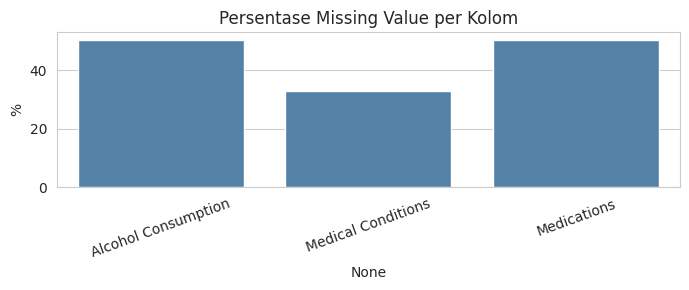

In [56]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    "Jumlah Missing": missing,
    "Persentase (%)": missing_pct
})
missing_df = missing_df[missing_df["Jumlah Missing"] > 0]

if missing_df.empty:
    print("Tidak ada missing value")
else:
    print("Kolom dengan missing value:")
    display(missing_df)

    # Visualisasi
    plt.figure(figsize=(7, 3))
    sns.barplot(x=missing_df.index, y=missing_df["Persentase (%)"], color="steelblue")
    plt.title("Persentase Missing Value per Kolom")
    plt.ylabel("%")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

### **3. Cek & Hapus Duplikat**

In [57]:
# Duplikat berdasarkan seluruh kolom
dup_all = df.duplicated().sum()
print("Duplikat (semua kolom)       :", dup_all)

Duplikat (semua kolom)       : 0


In [58]:
print("Deskripsi Dataset")
print(display(df.describe().T))

Deskripsi Dataset


,count,mean,std,min,25%,50%,75%,max
Id,1958.0,1.549929e+06,261424.953731,1100064.0,1319163.0,1546027.5,1775870.5,1999676.0
Age,1958.0,3.910112e+01,21.355424,18.0,21.0,32.0,53.0,90.0
Osteoporosis,1958.0,5.000000e-01,0.500128,0.0,0.0,0.5,1.0,1.0


None


### **4. Analisis Deskriptif**

### 4.1 Statistik Deskriptif

In [59]:
target = "Osteoporosis"
cat_cols = [c for c in df.columns if c not in ["Id", "Age", target]]

df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,1958.0,NaN,NaN,NaN,1549928.629724,261424.953731,1100064.0,1319163.0,1546027.5,1775870.5,1999676.0
Age,1958.0,NaN,NaN,NaN,39.101124,21.355424,18.0,21.0,32.0,53.0,90.0
Gender,1958,2,Male,992,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hormonal Changes,1958,2,Normal,981,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Family History,1958,2,No,998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Race/Ethnicity,1958,3,African American,681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Body Weight,1958,2,Normal,1027,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Calcium Intake,1958,2,Low,1004,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vitamin D Intake,1958,2,Sufficient,1011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Physical Activity,1958,2,Active,1021,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 4.2 Distribusi Target

Osteoporosis
0    979
1    979
Name: count, dtype: int64
Osteoporosis
0    50.0 %
1    50.0 %
Name: count, dtype: object


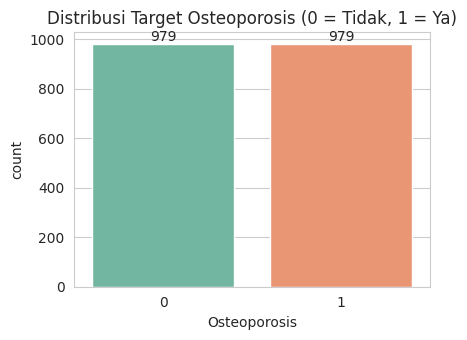

In [60]:
dist = df[target].value_counts().sort_index()
print(dist)
print((dist / len(df) * 100).round(2).astype(str) + " %")

plt.figure(figsize=(4.5, 3.5))
ax = sns.countplot(x=target, data=df, palette="Set2")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribusi Target Osteoporosis (0 = Tidak, 1 = Ya)")
plt.tight_layout()
plt.show()


### 4.3 Distribusi Age

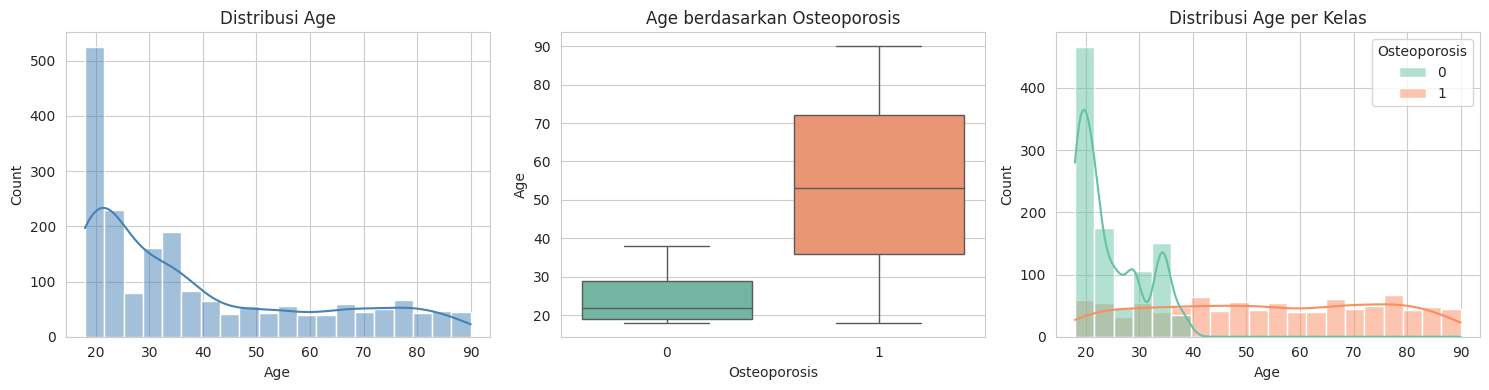

              count   mean    std   min   25%   50%   75%   max
Osteoporosis                                                   
0             979.0  24.34   6.11  18.0  19.0  22.0  29.0  38.0
1             979.0  53.86  20.96  18.0  36.0  53.0  72.0  90.0


In [61]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["Age"], bins=20, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi Age")

sns.boxplot(x=target, y="Age", data=df, palette="Set2", ax=axes[1])
axes[1].set_title("Age berdasarkan Osteoporosis")

sns.histplot(data=df, x="Age", hue=target, bins=20, kde=True,
             palette="Set2", ax=axes[2])
axes[2].set_title("Distribusi Age per Kelas")

plt.tight_layout()
plt.show()

print(df.groupby(target)["Age"].describe().round(2))

### 4.4 Distribusi Fitur Kategorikal terhadap Target

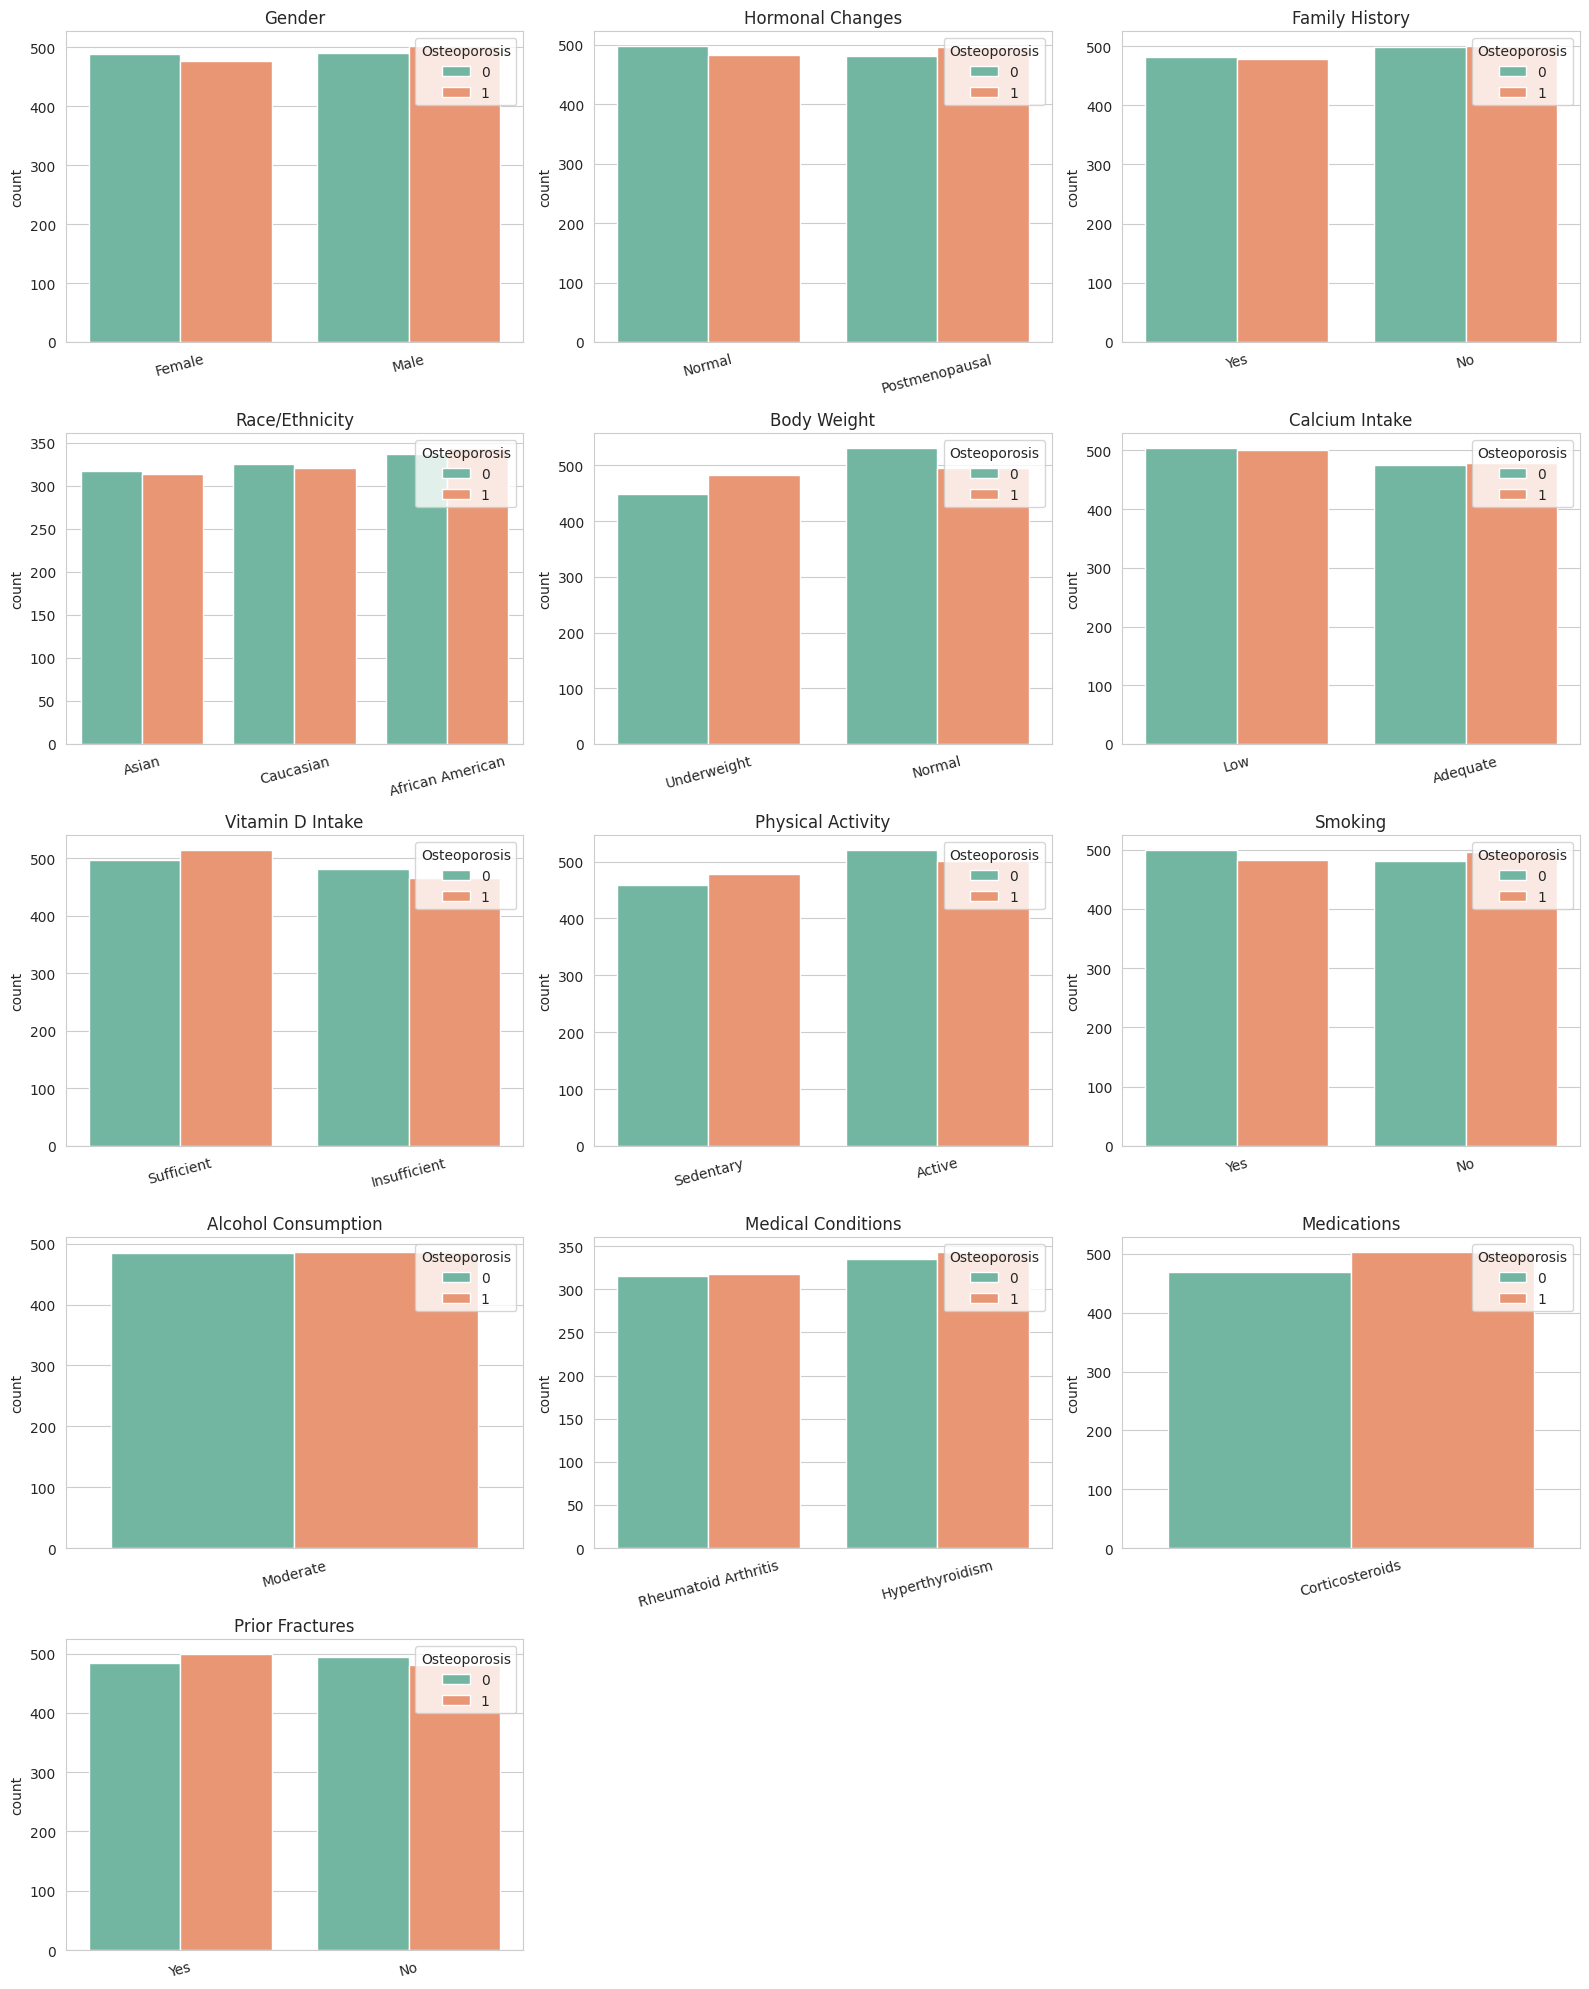

In [62]:
n = len(cat_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(x=col, hue=target, data=df, palette="Set2", ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=15)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### 4.5 Proporsi Osteoporosis per Kategori

In [63]:
for col in cat_cols:
    r = df.groupby(col)[target].mean().round(3)
    print(f"{col:22s}", r.to_dict())

Gender                 {'Female': 0.494, 'Male': 0.506}
Hormonal Changes       {'Normal': 0.492, 'Postmenopausal': 0.508}
Family History         {'No': 0.501, 'Yes': 0.499}
Race/Ethnicity         {'African American': 0.505, 'Asian': 0.498, 'Caucasian': 0.497}
Body Weight            {'Normal': 0.483, 'Underweight': 0.519}
Calcium Intake         {'Adequate': 0.502, 'Low': 0.498}
Vitamin D Intake       {'Insufficient': 0.491, 'Sufficient': 0.508}
Physical Activity      {'Active': 0.491, 'Sedentary': 0.51}
Smoking                {'No': 0.508, 'Yes': 0.492}
Alcohol Consumption    {'Moderate': 0.501}
Medical Conditions     {'Hyperthyroidism': 0.506, 'Rheumatoid Arthritis': 0.502}
Medications            {'Corticosteroids': 0.517}
Prior Fractures        {'No': 0.492, 'Yes': 0.508}


##**Split Data**

In [67]:
#Cell – Data Split (80% train, 20% test)
from sklearn.model_selection import train_test_split

print("Spliting Data")
target = "Osteoporosis"

df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df[target]
)

print(f"Data train : {df_train.shape}")
print(f"Data test  : {df_test.shape}")

# Cell – Cek proporsi kelas setelah split
cek = pd.DataFrame({
    "Seluruh data": df[target].value_counts(normalize=True).round(3),
    "Train": df_train[target].value_counts(normalize=True).round(3),
    "Test": df_test[target].value_counts(normalize=True).round(3),
})
display(cek)

print("\nJumlah per kelas:")
print("Train:", df_train[target].value_counts().to_dict())
print("Test :", df_test[target].value_counts().to_dict())

Spliting Data
Data train : (1566, 16)
Data test  : (392, 16)


,Seluruh data,Train,Test
Osteoporosis,,,
0,0.5,0.5,0.5
1,0.5,0.5,0.5



Jumlah per kelas:
Train: {0: 783, 1: 783}
Test : {1: 196, 0: 196}


## **Preprocessing**

In [68]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# 1. Pisahkan fitur (X) dan target (y), sekaligus buang kolom Id
X_train = df_train.drop(columns=["Id", target])
y_train = df_train[target]
X_test  = df_test.drop(columns=["Id", target])
y_test  = df_test[target]

# 2. Tentukan kolom untuk tiap jenis encoding
ohe_cols = ["Race/Ethnicity", "Medical Conditions"]                  # kategori > 2
le_cols  = [c for c in X_train.select_dtypes(exclude="number").columns
            if c not in ohe_cols]                                    # kategori biner

# 3. Label Encoding (fit hanya di data train)
X_train_enc = X_train.copy()
X_test_enc  = X_test.copy()
label_encoders = {}

for col in le_cols:
    le = LabelEncoder()
    X_train_enc[col] = le.fit_transform(X_train[col])
    X_test_enc[col]  = le.transform(X_test[col])
    label_encoders[col] = le

# 4. One-Hot Encoding (fit hanya di data train)
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
ohe.fit(X_train[ohe_cols])

def terapkan_ohe(X_enc, X_raw):
    ohe_df = pd.DataFrame(
        ohe.transform(X_raw[ohe_cols]),
        columns=ohe.get_feature_names_out(ohe_cols),
        index=X_raw.index
    )
    return pd.concat([X_enc.drop(columns=ohe_cols), ohe_df], axis=1)

X_train_enc = terapkan_ohe(X_train_enc, X_train)
X_test_enc  = terapkan_ohe(X_test_enc, X_test)

# 5. Rapikan nama kolom (hindari spasi/simbol agar aman untuk XGBoost & LightGBM)
for d in (X_train_enc, X_test_enc):
    d.columns = d.columns.str.replace(r"[^0-9a-zA-Z_]", "_", regex=True)

print("X_train :", X_train_enc.shape)
print("X_test  :", X_test_enc.shape)
print("Kolom sama antara train & test:", list(X_train_enc.columns) == list(X_test_enc.columns))

print("\nMapping Label Encoding:")
for col, le in label_encoders.items():
    print(f"  {col:20s}", dict(zip(le.classes_, le.transform(le.classes_))))

X_train_enc.head()

X_train : (1566, 18)
X_test  : (392, 18)
Kolom sama antara train & test: True

Mapping Label Encoding:
  Gender               {'Female': np.int64(0), 'Male': np.int64(1)}
  Hormonal Changes     {'Normal': np.int64(0), 'Postmenopausal': np.int64(1)}
  Family History       {'No': np.int64(0), 'Yes': np.int64(1)}
  Body Weight          {'Normal': np.int64(0), 'Underweight': np.int64(1)}
  Calcium Intake       {'Adequate': np.int64(0), 'Low': np.int64(1)}
  Vitamin D Intake     {'Insufficient': np.int64(0), 'Sufficient': np.int64(1)}
  Physical Activity    {'Active': np.int64(0), 'Sedentary': np.int64(1)}
  Smoking              {'No': np.int64(0), 'Yes': np.int64(1)}
  Alcohol Consumption  {'Moderate': np.int64(0), nan: np.int64(1)}
  Medications          {'Corticosteroids': np.int64(0), nan: np.int64(1)}
  Prior Fractures      {'No': np.int64(0), 'Yes': np.int64(1)}


,Age,Gender,Hormonal_Changes,Family_History,Body_Weight,Calcium_Intake,Vitamin_D_Intake,Physical_Activity,Smoking,Alcohol_Consumption,Medications,Prior_Fractures,Race_Ethnicity_African_American,Race_Ethnicity_Asian,Race_Ethnicity_Caucasian,Medical_Conditions_Hyperthyroidism,Medical_Conditions_Rheumatoid_Arthritis,Medical_Conditions_nan
1473,25,0,1,0,0,1,0,1,0,0,0,0,0.0,0.0,1.0,1.0,0.0,0.0
1394,34,1,1,1,0,1,0,0,0,0,1,0,0.0,1.0,0.0,0.0,1.0,0.0
718,25,0,1,0,1,1,0,0,0,0,1,0,0.0,0.0,1.0,1.0,0.0,0.0
868,64,0,1,1,1,0,0,1,1,0,0,0,1.0,0.0,0.0,0.0,0.0,1.0
256,44,1,1,1,1,0,1,0,0,0,1,1,1.0,0.0,0.0,1.0,0.0,0.0
